In [1]:

import pandas as pd

path = "/kaggle/input/competitions/ieee-fraud-detection/"

transactions = pd.read_csv(path + "train_transaction.csv")
identity = pd.read_csv(path + "train_identity.csv")

df = transactions.merge(identity, on="TransactionID", how="left")

print("Shape:", df.shape)
print("\nFraud distribution:")
print(df["isFraud"].value_counts())
print("\nFraud rate:", round(df["isFraud"].mean() * 100, 2), "%")

df.head()


Shape: (590540, 434)

Fraud distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud rate: 3.5 %


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [2]:
print("Memory:", round(df.memory_usage(deep=True).sum() / 1024**3, 2), "GB")

missing = df.isna().mean() * 100

print("Columns with >90% missing:", (missing > 90).sum())
print("Columns with 50–90% missing:", ((missing > 50) & (missing <= 90)).sum())
print("Columns with <=50% missing:", (missing <= 50).sum())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMost missing columns:")
print(missing.sort_values(ascending=False).head(15).round(1))

Memory: 2.46 GB
Columns with >90% missing: 12
Columns with 50–90% missing: 202
Columns with <=50% missing: 220

Data types:
float64    399
object      31
int64        4
Name: count, dtype: int64

Most missing columns:
id_24    99.2
id_25    99.1
id_07    99.1
id_08    99.1
id_21    99.1
id_26    99.1
id_27    99.1
id_23    99.1
id_22    99.1
dist2    93.6
D7       93.4
id_18    92.4
D13      89.5
D14      89.5
D12      89.0
dtype: float64


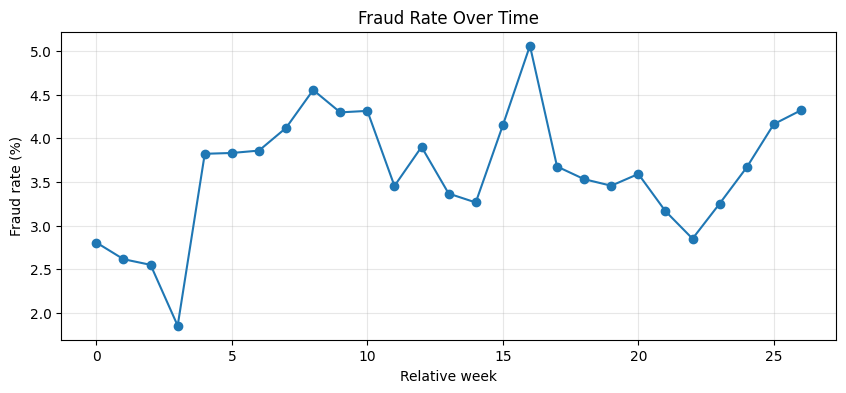

,mean,count,fraud_rate
week,,,
0,0.028055,23810,2.805544
1,0.026148,27803,2.614826
2,0.025500,34470,2.550044
3,0.018523,37251,1.852299
4,0.038226,24041,3.822636


In [3]:
import matplotlib.pyplot as plt

# TransactionDT is measured in seconds
df["week"] = (df["TransactionDT"] // 604800).astype(int)

weekly = df.groupby("week")["isFraud"].agg(["mean", "count"])
weekly["fraud_rate"] = weekly["mean"] * 100

plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly["fraud_rate"], marker="o")
plt.xlabel("Relative week")
plt.ylabel("Fraud rate (%)")
plt.title("Fraud Rate Over Time")
plt.grid(alpha=0.3)
plt.show()

weekly.head()

            count    mean     std   min    25%   50%    75%       max
isFraud                                                              
0        569877.0  134.51  239.40  0.25  43.97  68.5  120.0  31937.39
1         20663.0  149.24  232.21  0.29  35.04  75.0  161.0   5191.00


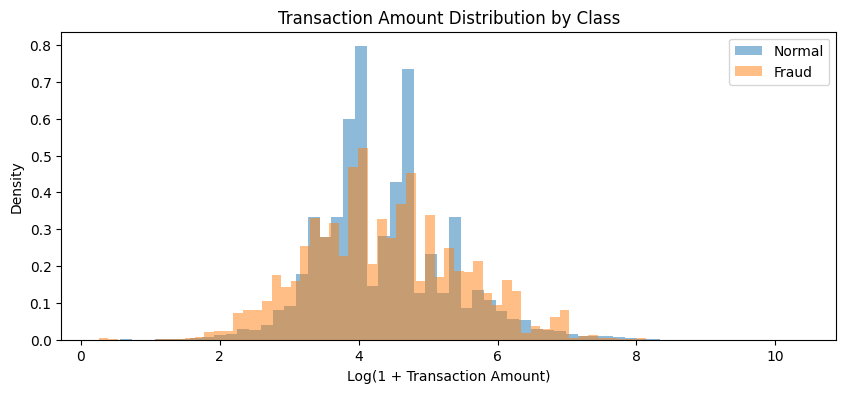

In [4]:
import numpy as np
print(df.groupby("isFraud")["TransactionAmt"].describe().round(2))

plt.figure(figsize=(10, 4))

for label, name in [(0, "Normal"), (1, "Fraud")]:
    amounts = df.loc[df["isFraud"] == label, "TransactionAmt"]
    plt.hist(np.log1p(amounts), bins=60, alpha=0.5,
             density=True, label=name)

plt.xlabel("Log(1 + Transaction Amount)")
plt.ylabel("Density")
plt.title("Transaction Amount Distribution by Class")
plt.legend()
plt.show()

           mean   count  fraud_rate
ProductCD                          
C          0.12   68519       11.69
H          0.05   33024        4.77
R          0.04   37699        3.78
S          0.06   11628        5.90
W          0.02  439670        2.04


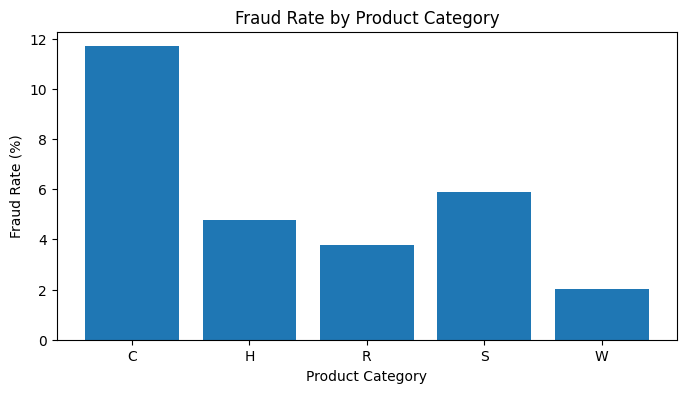

In [5]:
product = df.groupby("ProductCD")["isFraud"].agg(["mean", "count"])
product["fraud_rate"] = product["mean"] * 100

print(product.round(2))

plt.figure(figsize=(8, 4))
plt.bar(product.index, product["fraud_rate"])
plt.xlabel("Product Category")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Product Category")
plt.show()

                  mean   count  fraud_rate
card4                                     
american express  0.03    8328        2.87
discover          0.08    6651        7.73
mastercard        0.03  189217        3.43
visa              0.03  384767        3.48


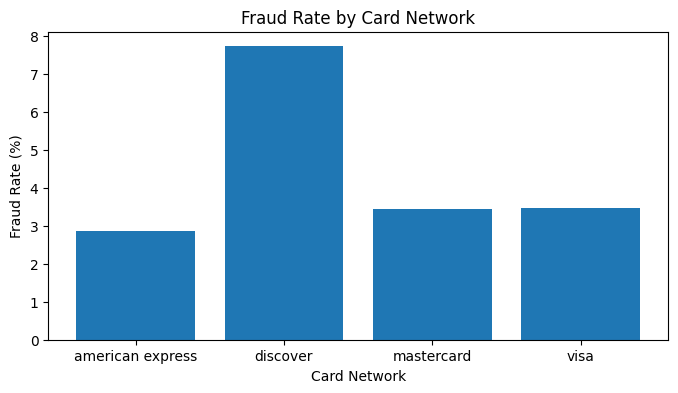

In [6]:
card = df.groupby("card4")["isFraud"].agg(["mean", "count"])
card["fraud_rate"] = card["mean"] * 100

print(card.round(2))

plt.figure(figsize=(8, 4))
plt.bar(card.index, card["fraud_rate"])
plt.xlabel("Card Network")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Card Network")
plt.show()

In [7]:
# Sort transactions chronologically
df = df.sort_values("TransactionDT").reset_index(drop=True)

n = len(df)
train = df.iloc[:int(n * 0.6)]
val = df.iloc[int(n * 0.6):int(n * 0.8)]
test = df.iloc[int(n * 0.8):]

for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {data.shape} | Fraud rate: {data['isFraud'].mean()*100:.2f}%")

Train: (354324, 435) | Fraud rate: 3.38%
Validation: (118108, 435) | Fraud rate: 3.90%
Test: (118108, 435) | Fraud rate: 3.44%


In [8]:
features = [
    "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
    "DeviceType", "DeviceInfo"
]

info = pd.DataFrame({
    "Missing (%)": train[features].isna().mean() * 100,
    "Unique values": train[features].nunique()
})

print(info.round(2))

                Missing (%)  Unique values
TransactionAmt         0.00          14349
ProductCD              0.00              5
card1                  0.00          11735
card2                  1.71            499
card3                  0.23            102
card4                  0.23              4
card5                  0.75            108
card6                  0.23              4
addr1                 10.99            308
addr2                 10.99             64
dist1                 62.17           2539
dist2                 92.52           1543
P_emaildomain         15.97             59
R_emaildomain         74.45             60
DeviceType            73.17              2
DeviceInfo            76.89           1446


In [9]:
families = {
    "C": [f"C{i}" for i in range(1, 15)],
    "D": [f"D{i}" for i in range(1, 16)],
    "M": [f"M{i}" for i in range(1, 10)],
    "V": [f"V{i}" for i in range(1, 340)]
}

for name, cols in families.items():
    cols = [c for c in cols if c in train.columns]
    missing = train[cols].isna().mean()

    print(f"\n{name} features: {len(cols)}")
    print("<= 20% missing:", (missing <= 0.20).sum())
    print("<= 50% missing:", (missing <= 0.50).sum())
    print("> 90% missing:", (missing > 0.90).sum())


C features: 14
<= 20% missing: 14
<= 50% missing: 14
> 90% missing: 0

D features: 15
<= 20% missing: 3
<= 50% missing: 5
> 90% missing: 1

M features: 9
<= 20% missing: 0
<= 50% missing: 2
> 90% missing: 0

V features: 339
<= 20% missing: 151
<= 50% missing: 169
> 90% missing: 0


In [10]:
missing = train.isna().mean()

base = [
    "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "P_emaildomain"
]

C = [f"C{i}" for i in range(1, 15)]
D = [f"D{i}" for i in range(1, 16) if missing[f"D{i}"] <= 0.20]
M = [f"M{i}" for i in range(1, 10) if missing[f"M{i}"] <= 0.50]

V = missing[[f"V{i}" for i in range(1, 340)]].sort_values().head(30).index.tolist()

features = base + C + D + M + V

print("Selected features:", len(features))
print("\nNumerical:", train[features].select_dtypes(include="number").shape[1])
print("Categorical:", train[features].select_dtypes(include="object").shape[1])
print("\nSelected D features:", D)
print("Selected M features:", M)

Selected features: 62

Numerical: 56
Categorical: 6

Selected D features: ['D1', 'D10', 'D15']
Selected M features: ['M4', 'M6']


In [11]:
import numpy as np

cycle = 2 * np.pi * (df["TransactionDT"] % 86400) / 86400

df["time_sin"] = np.sin(cycle)
df["time_cos"] = np.cos(cycle)

features += ["time_sin", "time_cos"]

# Refresh the chronological splits
train = df.iloc[:354324].copy()
val = df.iloc[354324:472432].copy()
test = df.iloc[472432:].copy()

print("Total features:", len(features))
df[["TransactionDT", "time_sin", "time_cos"]].head()

Total features: 64


,TransactionDT,time_sin,time_cos
0,86400,0.000000,1.000000
1,86401,0.000073,1.000000
2,86469,0.005018,0.999987
3,86499,0.007199,0.999974
4,86506,0.007708,0.999970


In [12]:
proxy_cols = ["card1", "card2", "card3", "card5", "addr1"]

groups = train.groupby(proxy_cols, dropna=False).size()

print("Total groups:", len(groups))
print("Groups with 2+ transactions:", (groups >= 2).sum())
print("Largest group:", groups.max())

repeated = groups[groups >= 2].sum()
print("Transactions in repeated groups:",
      round(repeated / len(train) * 100, 2), "%")

Total groups: 34864
Groups with 2+ transactions: 20036
Largest group: 5901
Transactions in repeated groups: 95.82 %


In [13]:
proxy_cols = ["card1", "card2", "card3", "card5", "addr1"]

# df is already sorted chronologically
df["time_since_prev"] = (
    df.groupby(proxy_cols)["TransactionDT"].diff() / 60
)

# Same-second ordering is ambiguous
df.loc[df["time_since_prev"] == 0, "time_since_prev"] = np.nan

features.append("time_since_prev")

# Refresh splits
train = df.iloc[:354324].copy()
val = df.iloc[354324:472432].copy()
test = df.iloc[472432:].copy()

print("Total features:", len(features))
print("History available:", round(train["time_since_prev"].notna().mean() * 100, 2), "%")
print("Median interval (minutes):", train["time_since_prev"].median())

train[["TransactionDT", "card1", "time_since_prev"]].dropna().head(10)

Total features: 65
History available: 78.19 %
Median interval (minutes): 667.0


,TransactionDT,card1,time_since_prev
51,87328,7835,5.333333
61,87596,12544,5.183333
69,87725,12866,19.000000
73,87759,1955,5.316667
75,87779,4806,10.500000
77,87793,3278,3.033333
81,87868,17188,3.633333
89,88042,17188,2.900000
103,88184,18370,13.050000
104,88208,16659,0.650000


In [14]:
df["tx_1h"] = np.nan
df["tx_24h"] = np.nan

for _, group in df.groupby(proxy_cols, sort=False):
    times = group["TransactionDT"].to_numpy()

    # Exclude current and same-second transactions
    end = np.searchsorted(times, times, side="left")

    count_1h = end - np.searchsorted(times, times - 3600)
    count_24h = end - np.searchsorted(times, times - 86400)

    df.loc[group.index, "tx_1h"] = count_1h
    df.loc[group.index, "tx_24h"] = count_24h

features += ["tx_1h", "tx_24h"]

# Refresh chronological splits
train = df.iloc[:354324].copy()
val = df.iloc[354324:472432].copy()
test = df.iloc[472432:].copy()

print("Total features:", len(features))
print(train[["tx_1h", "tx_24h"]].describe().round(2))

Total features: 67
           tx_1h     tx_24h
count  308416.00  308416.00
mean        0.36       3.73
std         0.87       7.55
min         0.00       0.00
25%         0.00       0.00
50%         0.00       1.00
75%         0.00       4.00
max        19.00      87.00


In [15]:
df["amt_ratio_30d"] = np.nan

window = 30 * 24 * 3600  # 30 days in seconds

for _, group in df.groupby(proxy_cols, sort=False):
    times = group["TransactionDT"].to_numpy()
    amounts = group["TransactionAmt"].to_numpy()

    start = np.searchsorted(times, times - window)
    end = np.searchsorted(times, times, side="left")

    sums = np.r_[0, amounts.cumsum()]
    counts = end - start

    avg = np.divide(
        sums[end] - sums[start],
        counts,
        out=np.full(len(group), np.nan),
        where=counts > 0
    )

    ratio = np.divide(
        amounts, avg,
        out=np.full(len(group), np.nan),
        where=avg > 0
    )

    df.loc[group.index, "amt_ratio_30d"] = ratio

features.append("amt_ratio_30d")

# Refresh splits
train = df.iloc[:354324].copy()
val = df.iloc[354324:472432].copy()
test = df.iloc[472432:].copy()

print("Total features:", len(features))
print("History available:",
      round(train["amt_ratio_30d"].notna().mean() * 100, 2), "%")

print(train["amt_ratio_30d"].describe().round(2))

Total features: 68
History available: 76.42 %
count    270762.00
mean          1.20
std           2.07
min           0.01
25%           0.42
50%           0.74
75%           1.26
max         136.64
Name: amt_ratio_30d, dtype: float64


In [16]:
categorical = [
    "ProductCD", "card1", "card2", "card3",
    "card4", "card5", "card6",
    "addr1", "addr2", "P_emaildomain",
    "M4", "M6"
]

numerical = [c for c in features if c not in categorical]

print("Numerical features:", len(numerical))
print("Categorical features:", len(categorical))

print("\nCategorical cardinality:")
print(train[categorical].nunique().sort_values(ascending=False))

Numerical features: 56
Categorical features: 12

Categorical cardinality:
card1            11735
card2              499
addr1              308
card5              108
card3              102
addr2               64
P_emaildomain       59
ProductCD            5
card6                4
card4                4
M4                   3
M6                   2
dtype: int64


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

cat_pipe = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    max_categories=20,
    sparse_output=True
)

preprocessor = ColumnTransformer([
    ("num", num_pipe, numerical),
    ("cat", cat_pipe, categorical)
], sparse_threshold=1.0)

# Fit on training data only
X_train = preprocessor.fit_transform(train[features])

print("Original shape:", train[features].shape)
print("Transformed shape:", X_train.shape)
print("Sparse matrix:", hasattr(X_train, "nnz"))

Original shape: (354324, 68)
Transformed shape: (354324, 226)
Sparse matrix: True


In [18]:
# Transform without refitting
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])

# Target: 1 = Fraud, 0 = Normal
y_train = train["isFraud"]
y_val = val["isFraud"]
y_test = test["isFraud"]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (354324, 226) (354324,)
Validation: (118108, 226) (118108,)
Test: (118108, 226) (118108,)


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, fbeta_score,
    matthews_corrcoef, confusion_matrix
)

lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    tol=1e-3,
    random_state=42
)

lr.fit(X_train, y_train)

lr_scores = lr.predict_proba(X_val)[:, 1]
lr_pred = (lr_scores >= 0.5).astype(int)

print("Iterations:", lr.n_iter_[0])
print("PR-AUC:", round(average_precision_score(y_val, lr_scores), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, lr_scores), 4))
print("Precision:", round(precision_score(y_val, lr_pred), 4))
print("Recall:", round(recall_score(y_val, lr_pred), 4))
print("F2:", round(fbeta_score(y_val, lr_pred, beta=2), 4))
print("MCC:", round(matthews_corrcoef(y_val, lr_pred), 4))
print("Alerts:", lr_pred.sum())

Iterations: 119
PR-AUC: 0.2942
ROC-AUC: 0.8365
Precision: 0.0784
Recall: 0.8848
F2: 0.2893
MCC: 0.1802
Alerts: 52072


In [20]:
from xgboost import XGBClassifier

# Fraud imbalance ratio
weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=weight,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_scores = xgb.predict_proba(X_val)[:, 1]
xgb_pred = (xgb_scores >= 0.5).astype(int)

print("Best iteration:", xgb.best_iteration)
print("PR-AUC:", round(average_precision_score(y_val, xgb_scores), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, xgb_scores), 4))
print("Precision:", round(precision_score(y_val, xgb_pred), 4))
print("Recall:", round(recall_score(y_val, xgb_pred), 4))
print("F2:", round(fbeta_score(y_val, xgb_pred, beta=2), 4))
print("MCC:", round(matthews_corrcoef(y_val, xgb_pred), 4))
print("Alerts:", xgb_pred.sum())

Best iteration: 398
PR-AUC: 0.5379
ROC-AUC: 0.913
Precision: 0.2203
Recall: 0.7692
F2: 0.5134
MCC: 0.3718
Alerts: 16103


In [21]:
from sklearn.ensemble import IsolationForest

# Random training sample, without using labels
rng = np.random.default_rng(42)
idx = rng.choice(X_train.shape[0], 100_000, replace=False)

iso = IsolationForest(
    n_estimators=150,
    max_samples=256,
    random_state=42,
    n_jobs=-1
)

iso.fit(X_train[idx])

# Higher score = more anomalous
iso_scores = -iso.decision_function(X_val)

print("PR-AUC:", round(average_precision_score(y_val, iso_scores), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, iso_scores), 4))

PR-AUC: 0.1618
ROC-AUC: 0.7218


In [22]:
k = 500

for name, scores in [
    ("Logistic Regression", lr_scores),
    ("XGBoost", xgb_scores),
    ("Isolation Forest", iso_scores)
]:
    top = np.argsort(scores)[-k:]
    frauds = y_val.iloc[top].sum()

    print(f"\n{name}")
    print("Frauds in top 500:", frauds)
    print("Precision@500:", round(frauds / k, 4))
    print("Recall@500:", round(frauds / y_val.sum(), 4))


Logistic Regression
Frauds in top 500: 373
Precision@500: 0.746
Recall@500: 0.0809

XGBoost
Frauds in top 500: 454
Precision@500: 0.908
Recall@500: 0.0985

Isolation Forest
Frauds in top 500: 275
Precision@500: 0.55
Recall@500: 0.0596


In [23]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

train_idx = rng.choice(X_train.shape[0], 5000, replace=False)
val_idx = np.linspace(0, X_val.shape[0] - 1, 20000, dtype=int)

# Reduce dimensionality for faster neighbour search
svd = TruncatedSVD(n_components=15, random_state=42)

Z_train = svd.fit_transform(X_train[train_idx])
Z_val = svd.transform(X_val[val_idx])

scaler = StandardScaler()
Z_train = scaler.fit_transform(Z_train)
Z_val = scaler.transform(Z_val)

# Train LOF without fraud labels
lof = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
)

lof.fit(Z_train)

# Higher score = more anomalous
lof_scores = -lof.score_samples(Z_val)

y_val_sample = y_val.iloc[val_idx]

print("PR-AUC:", round(average_precision_score(y_val_sample, lof_scores), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_sample, lof_scores), 4))

PR-AUC: 0.0934
ROC-AUC: 0.6546


In [24]:
scores = {
    "Logistic Regression": lr_scores[val_idx],
    "XGBoost": xgb_scores[val_idx],
    "Isolation Forest": iso_scores[val_idx],
    "LOF": lof_scores
}

k = 100
results = []

for name, s in scores.items():
    top = np.argsort(s)[-k:]
    frauds = y_val_sample.iloc[top].sum()

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val_sample, s),
        "ROC-AUC": roc_auc_score(y_val_sample, s),
        "Precision@100": frauds / k,
        "Recall@100": frauds / y_val_sample.sum()
    })

comparison = pd.DataFrame(results).set_index("Model")
print(comparison.round(4))

                     PR-AUC  ROC-AUC  Precision@100  Recall@100
Model                                                          
Logistic Regression  0.3069   0.8358           0.75      0.0934
XGBoost              0.5346   0.9062           0.90      0.1121
Isolation Forest     0.1553   0.7239           0.47      0.0585
LOF                  0.0934   0.6546           0.21      0.0262


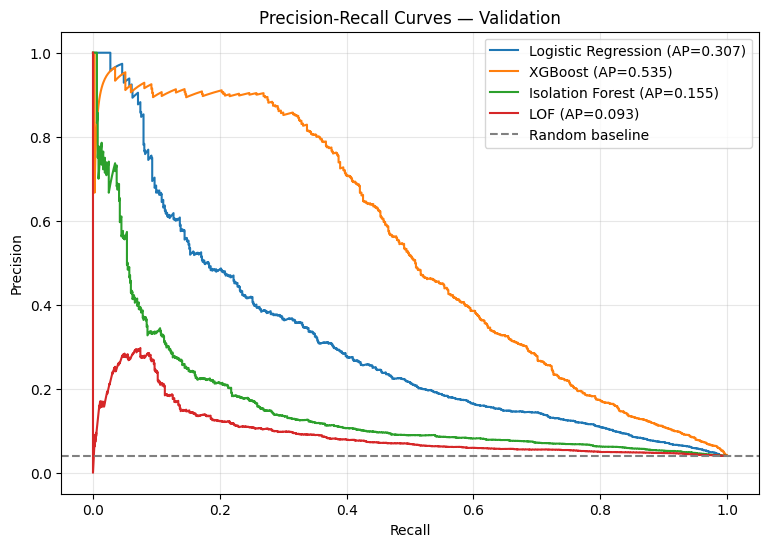

In [25]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(9, 6))

for name, s in scores.items():
    precision, recall, _ = precision_recall_curve(y_val_sample, s)
    ap = average_precision_score(y_val_sample, s)

    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

# Random-ranking baseline
plt.axhline(
    y_val_sample.mean(),
    color="gray", linestyle="--",
    label="Random baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [26]:
from sklearn.metrics import fbeta_score, matthews_corrcoef

k = 100
results = []

for name, s in scores.items():
    pred = np.zeros(len(s), dtype=int)

    # Flag the 100 most suspicious transactions
    top = np.argsort(s)[-k:]
    pred[top] = 1

    results.append({
        "Model": name,
        "Alerts": pred.sum(),
        "F2": fbeta_score(y_val_sample, pred, beta=2),
        "MCC": matthews_corrcoef(y_val_sample, pred)
    })

metrics = pd.DataFrame(results).set_index("Model")
print(metrics.round(4))

                     Alerts      F2     MCC
Model                                      
Logistic Regression     100  0.1132  0.2563
XGBoost                 100  0.1359  0.3105
Isolation Forest        100  0.0710  0.1552
LOF                     100  0.0317  0.0613


In [27]:
cost_per_alert = 5
amounts = val["TransactionAmt"].to_numpy()
y = y_val.to_numpy()

results = []

for threshold in np.linspace(0, 1, 101):
    pred = xgb_scores >= threshold

    missed_loss = amounts[(y == 1) & (~pred)].sum()
    alert_cost = pred.sum() * cost_per_alert
    total_cost = missed_loss + alert_cost

    results.append({
        "threshold": threshold,
        "alerts": pred.sum(),
        "cost": total_cost
    })

cost_df = pd.DataFrame(results)

best = cost_df.loc[cost_df["cost"].idxmin()]

print("Best threshold:", round(best["threshold"], 2))
print("Number of alerts:", int(best["alerts"]))
print("Minimum cost:", round(best["cost"], 2))

print("Cost without model:",
      round(amounts[y == 1].sum(), 2))

Best threshold: 0.39
Number of alerts: 24364
Minimum cost: 247161.48
Cost without model: 796119.85


In [28]:
threshold = float(best["threshold"])
pred = (xgb_scores >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

print("Threshold:", threshold)
print("TP:", tp, "| FP:", fp, "| FN:", fn, "| TN:", tn)

print("\nPrecision:", round(precision_score(y_val, pred), 4))
print("Recall:", round(recall_score(y_val, pred), 4))
print("F2:", round(fbeta_score(y_val, pred, beta=2), 4))
print("MCC:", round(matthews_corrcoef(y_val, pred), 4))

missed_loss = amounts[(y == 1) & (pred == 0)].sum()
alert_cost = pred.sum() * cost_per_alert

print("\nMissed fraud loss:", round(missed_loss, 2))
print("Investigation cost:", round(alert_cost, 2))
print("Total cost:", round(missed_loss + alert_cost, 2))

Threshold: 0.39
TP: 3886 | FP: 20478 | FN: 725 | TN: 93019

Precision: 0.1595
Recall: 0.8428
F2: 0.4539
MCC: 0.317

Missed fraud loss: 125341.48
Investigation cost: 121820
Total cost: 247161.48


In [29]:
budgets = [500, 1000, 2500, 5000, 10000, 20000]

order = np.argsort(xgb_scores)[::-1]
results = []

for k in budgets:
    pred = np.zeros(len(y_val), dtype=int)
    pred[order[:k]] = 1

    missed = (y == 1) & (pred == 0)
    cost = amounts[missed].sum() + 5 * k

    results.append({
        "Budget": k,
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F2": fbeta_score(y_val, pred, beta=2),
        "MCC": matthews_corrcoef(y_val, pred),
        "Cost": cost
    })

budget_df = pd.DataFrame(results)
print(budget_df.round(4))

   Budget  Precision  Recall      F2     MCC        Cost
0     500     0.9080  0.0985  0.1198  0.2925  763893.894
1    1000     0.9050  0.1963  0.2327  0.4131  734014.828
2    2500     0.7200  0.3904  0.4297  0.5170  588257.904
3    5000     0.4892  0.5305  0.5217  0.4886  439368.204
4   10000     0.3114  0.6753  0.5474  0.4277  314813.665
5   20000     0.1854  0.8044  0.4824  0.3413  256219.047


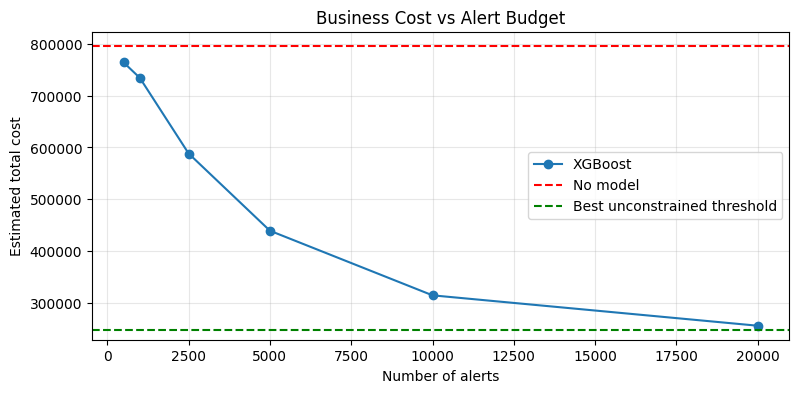

In [30]:
plt.figure(figsize=(9, 4))

plt.plot(budget_df["Budget"], budget_df["Cost"], marker="o",
         label="XGBoost")

plt.axhline(amounts[y == 1].sum(), linestyle="--",
            color="red", label="No model")

plt.axhline(best["cost"], linestyle="--",
            color="green", label="Best unconstrained threshold")

plt.xlabel("Number of alerts")
plt.ylabel("Estimated total cost")
plt.title("Business Cost vs Alert Budget")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
k = 10000

# Rank transactions by fraud probability
order = np.argsort(-xgb_scores, kind="stable")

# Select exactly k alerts
pred = np.zeros(len(xgb_scores), dtype=int)
pred[order[:k]] = 1

# Score at the budget boundary
threshold_k = xgb_scores[order[k - 1]]

print("Budget:", k)
print("Boundary score:", round(threshold_k, 4))
print("Alerts:", pred.sum())

print("Precision:", round(precision_score(y_val, pred), 4))
print("Recall:", round(recall_score(y_val, pred), 4))
print("F2:", round(fbeta_score(y_val, pred, beta=2), 4))
print("MCC:", round(matthews_corrcoef(y_val, pred), 4))

missed_loss = amounts[(y == 1) & (pred == 0)].sum()
cost = missed_loss + 5 * pred.sum()

print("Total cost:", round(cost, 2))

Budget: 10000
Boundary score: 0.6209
Alerts: 10000
Precision: 0.3114
Recall: 0.6753
F2: 0.5474
MCC: 0.4277
Total cost: 314813.66


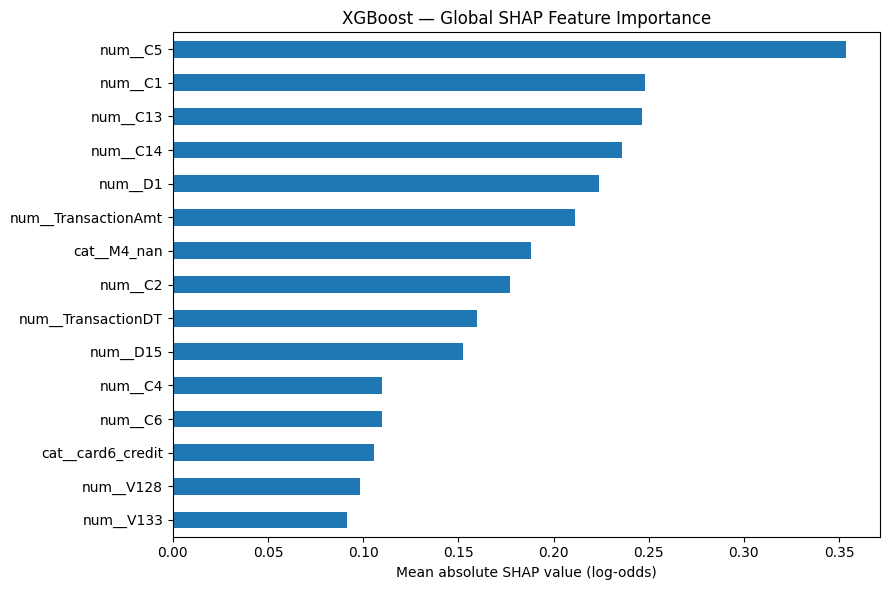

In [32]:
from xgboost import DMatrix

# Sample 300 validation transactions for explanations
rng = np.random.default_rng(42)
idx = rng.choice(X_val.shape[0], 300, replace=False)

# Compute TreeSHAP contributions
shap_values = xgb.get_booster().predict(
    DMatrix(X_val[idx]),
    pred_contribs=True,
    iteration_range=(0, xgb.best_iteration + 1)
)

# Last column is the baseline contribution
feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    np.abs(shap_values[:, :-1]).mean(axis=0),
    index=feature_names
).sort_values(ascending=False)

# Plot top 15 features
importance.head(15).sort_values().plot.barh(figsize=(9, 6))

plt.xlabel("Mean absolute SHAP value (log-odds)")
plt.title("XGBoost — Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

Transaction ID: 3341334
Actual label: 1
Fraud score: 0.9274


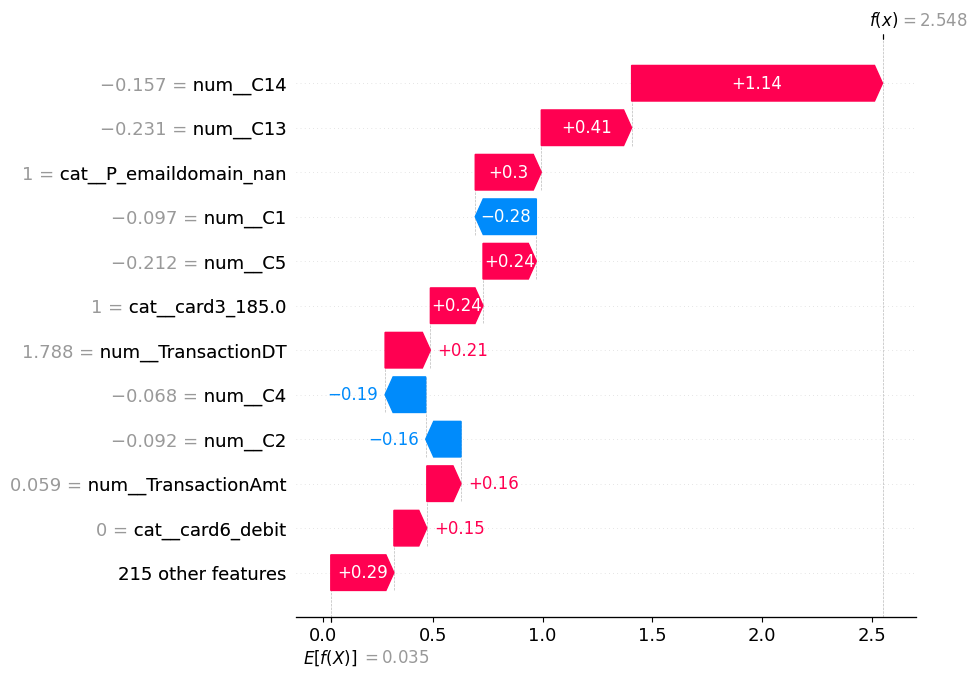

In [33]:
import shap
from xgboost import DMatrix

# Select a correctly detected fraud from validation
candidates = np.where(
    (y_val.to_numpy() == 1) & (xgb_scores >= threshold_k)
)[0]

i = candidates[0]

# Calculate SHAP for this transaction
contrib = xgb.get_booster().predict(
    DMatrix(X_val[i]),
    pred_contribs=True,
    iteration_range=(0, xgb.best_iteration + 1)
)[0]

explanation = shap.Explanation(
    values=contrib[:-1],
    base_values=contrib[-1],
    data=X_val[i].toarray().ravel(),
    feature_names=preprocessor.get_feature_names_out()
)

print("Transaction ID:", val.iloc[i]["TransactionID"])
print("Actual label:", y_val.iloc[i])
print("Fraud score:", round(xgb_scores[i], 4))

shap.plots.waterfall(explanation, max_display=12)

In [34]:
# SHAP contributions for the selected transaction
contributions = pd.Series(
    contrib[:-1],
    index=feature_names
)

# Top 5 positive contributions
top_reasons = contributions[contributions > 0].nlargest(5)

print("Transaction:", int(val.iloc[i]["TransactionID"]))
print("Fraud score:", round(xgb_scores[i], 4))
print("\nTop 5 alert reasons:")

for feature, value in top_reasons.items():
    print(f"{feature}: +{value:.3f}")

Transaction: 3341334
Fraud score: 0.9274

Top 5 alert reasons:
num__C14: +1.143
num__C13: +0.411
cat__P_emaildomain_nan: +0.301
num__C5: +0.243
cat__card3_185.0: +0.240


In [35]:
# Final XGBoost predictions on the untouched test set
test_scores = xgb.predict_proba(X_test)[:, 1]

y_true = y_test.to_numpy()
test_amounts = test["TransactionAmt"].to_numpy()

print("PR-AUC:", round(average_precision_score(y_true, test_scores), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, test_scores), 4))

# Evaluate both operating modes
predictions = {
    "Cost threshold (0.39)": (test_scores >= 0.39).astype(int)
}

# Exactly 10,000 highest-risk transactions
k = 10000
top = np.argsort(-test_scores, kind="stable")[:k]

budget_pred = np.zeros(len(test_scores), dtype=int)
budget_pred[top] = 1

predictions["Budget (10,000)"] = budget_pred

for name, pred in predictions.items():
    missed = (y_true == 1) & (pred == 0)
    cost = test_amounts[missed].sum() + 5 * pred.sum()

    print(f"\n{name}")
    print("Alerts:", pred.sum())
    print("Precision:", round(precision_score(y_true, pred), 4))
    print("Recall:", round(recall_score(y_true, pred), 4))
    print("F2:", round(fbeta_score(y_true, pred, beta=2), 4))
    print("MCC:", round(matthews_corrcoef(y_true, pred), 4))
    print("Estimated cost:", round(cost, 2))

print("\nNo-model cost:",
      round(test_amounts[y_true == 1].sum(), 2))

PR-AUC: 0.438
ROC-AUC: 0.8861

Cost threshold (0.39)
Alerts: 24675
Precision: 0.1318
Recall: 0.8
F2: 0.3971
MCC: 0.2744
Estimated cost: 250997.66

Budget (10,000)
Alerts: 10000
Precision: 0.2484
Recall: 0.6112
F2: 0.473
MCC: 0.3571
Estimated cost: 303874.18

No-model cost: 609934.34


In [36]:
import joblib
import json
from pathlib import Path

output = Path("/kaggle/working/fraud_artifacts")
output.mkdir(exist_ok=True)

# Save trained model and preprocessing
xgb.save_model(str(output / "xgboost_model.json"))
joblib.dump(preprocessor, output / "preprocessor.pkl")

# Save input schema and validation-selected settings
config = {
    "features": features,
    "categorical": categorical,
    "numerical": numerical,
    "cost_threshold": 0.39,
    "alert_budget": 10000,
    "cost_per_alert": 5,
    "best_iteration": int(xgb.best_iteration)
}

with open(output / "config.json", "w") as f:
    json.dump(config, f, indent=2)

# Example inputs for testing the API
train[features].sample(20, random_state=42).to_csv(
    output / "reference.csv", index=False
)

print("Saved files:")
for file in output.iterdir():
    print(file.name, round(file.stat().st_size / 1024**2, 2), "MB")

Saved files:
config.json 0.0 MB
xgboost_model.json 1.38 MB
reference.csv 0.01 MB
preprocessor.pkl 0.3 MB


In [37]:
# ============================================================
# FINAL EXPORT — Everything needed for the web dashboard
# ============================================================

from pathlib import Path
import json
import shutil
import platform
import sklearn
import xgboost

output = Path("/kaggle/working/fraud_artifacts")
output.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Full validation results (118,108 transactions)
#    Used for interactive metrics, thresholds and costs
# ------------------------------------------------------------

dashboard_val = val[
    [
        "TransactionID",
        "TransactionDT",
        "TransactionAmt",
        "ProductCD",
        "card4",
        "isFraud"
    ]
].copy().reset_index(drop=True)

dashboard_val["xgb_score"] = xgb_scores
dashboard_val["lr_score"] = lr_scores
dashboard_val["iso_score"] = iso_scores

# LOF was evaluated on only 20,000 validation samples.
# Keep NaN elsewhere rather than inventing predictions.
dashboard_val["lof_score"] = np.nan
dashboard_val.loc[val_idx, "lof_score"] = lof_scores

dashboard_val.to_csv(
    output / "dashboard_validation.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Feature-ready transactions for live API demonstrations
# ------------------------------------------------------------

demo_columns = ["TransactionID", "isFraud"] + features

demo = val[demo_columns].sample(
    n=2000,
    random_state=42
)

demo.to_csv(
    output / "demo_transactions.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Global SHAP importance
# ------------------------------------------------------------

importance.rename_axis("feature").reset_index(
    name="mean_abs_shap"
).to_csv(
    output / "global_shap_importance.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Model comparison (same 20,000-row validation subset)
# ------------------------------------------------------------

comparison.join(
    metrics[["F2", "MCC"]]
).to_csv(
    output / "model_comparison.csv"
)

# ------------------------------------------------------------
# 5. Business-cost analysis
# ------------------------------------------------------------

cost_df.to_csv(
    output / "threshold_costs.csv",
    index=False
)

budget_df.to_csv(
    output / "budget_analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Final test results (reporting only)
# ------------------------------------------------------------

test_summary = {
    "n_transactions": int(len(test)),
    "fraud_rate": float(y_test.mean()),
    "pr_auc": float(average_precision_score(y_test, test_scores)),
    "roc_auc": float(roc_auc_score(y_test, test_scores)),
    "no_model_cost": float(
        test_amounts[y_true == 1].sum()
    ),
    "policies": {}
}

for name, pred in predictions.items():
    missed = (y_true == 1) & (pred == 0)

    test_summary["policies"][name] = {
        "alerts": int(pred.sum()),
        "precision": float(precision_score(y_true, pred)),
        "recall": float(recall_score(y_true, pred)),
        "f2": float(fbeta_score(y_true, pred, beta=2)),
        "mcc": float(matthews_corrcoef(y_true, pred)),
        "estimated_cost": float(
            test_amounts[missed].sum() + 5 * pred.sum()
        )
    }

with open(output / "test_summary.json", "w") as f:
    json.dump(test_summary, f, indent=2)

# ------------------------------------------------------------
# 7. Environment versions for reproducibility
# ------------------------------------------------------------

versions = {
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__
}

with open(output / "versions.json", "w") as f:
    json.dump(versions, f, indent=2)

# ------------------------------------------------------------
# 8. Create ONE downloadable ZIP containing all artifacts
# ------------------------------------------------------------

archive = shutil.make_archive(
    "/kaggle/working/fraud_dashboard_bundle",
    "zip",
    root_dir="/kaggle/working",
    base_dir="fraud_artifacts"
)

print("Validation rows:", len(dashboard_val))
print("Demo transactions:", len(demo))
print("\nExported files:")

for file in sorted(output.iterdir()):
    print(f"  {file.name}: {file.stat().st_size / 1024**2:.2f} MB")

print("\nZIP ready:", archive)

Validation rows: 118108
Demo transactions: 2000

Exported files:
  budget_analysis.csv: 0.00 MB
  config.json: 0.00 MB
  dashboard_validation.csv: 10.00 MB
  demo_transactions.csv: 0.69 MB
  global_shap_importance.csv: 0.01 MB
  model_comparison.csv: 0.00 MB
  preprocessor.pkl: 0.30 MB
  reference.csv: 0.01 MB
  test_summary.json: 0.00 MB
  threshold_costs.csv: 0.00 MB
  versions.json: 0.00 MB
  xgboost_model.json: 1.38 MB

ZIP ready: /kaggle/working/fraud_dashboard_bundle.zip
